In [5]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import data
df = data.load("listings")
df.head()

/Users/quintongao/Documents/SSU-Data-Dash/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,...,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,...,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,...,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,...,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,...,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,...,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [7]:
import pandas as pd
pd.set_option('display.max_columns', None)
print(df.shape)
df.info()


(150000, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 22 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   ml_num                      150000 non-null  object        
 1   sold_price                  150000 non-null  float64       
 2   list_price                  150000 non-null  float64       
 3   date_listed                 150000 non-null  datetime64[us]
 4   date_sold                   150000 non-null  datetime64[us]
 5   days_on_market              150000 non-null  int64         
 6   house_type_name             150000 non-null  object        
 7   house_style                 150000 non-null  object        
 8   bedrooms                    150000 non-null  int64         
 9   washrooms                   150000 non-null  int64         
 10  parking_total               150000 non-null  int64         
 11  garage                    

lot_front and lot_depth have only 62737, meaning they are missing over half of the data.
We cannot use object for our model since they are not unmbers -> we need to determine which ones are necessary.
all of them is useful except for ml_num and remakrs(probably).
There are also columns that can't be used for input since we are predicting: sold_price, date_sold, days_on_market, hidden column 19, list_price(only allowed by the list-aware track)

In [9]:
summary = df.groupby("house_type_name").agg(
    sales=("sold_price", "size"),
    median_price=("sold_price", "median"),
    low_10pct=("sold_price", lambda s: s.quantile(0.10)),
    high_90pct=("sold_price", lambda s: s.quantile(0.90)),
    lot_missing_share=("lot_front", lambda s: s.isna().mean()),
)
summary.sort_values("median_price")

,sales,median_price,low_10pct,high_90pct,lot_missing_share
house_type_name,,,,,
Condo Apt,76374,644300.0,445700.0,995000.0,1.0
Co-Op Apt,729,646600.0,433560.0,1096800.0,1.0
Condo Townhouse,10160,786200.0,566790.0,1188230.0,1.0
Freehold Townhouse,5138,1146600.0,836540.0,1923920.0,0.0
Semi-Detached,14397,1179100.0,842800.0,1969920.0,0.0
Detached,43202,1367850.0,864510.0,2786700.0,0.0


Peak month per type:
house_type_name
Co-Op Apt             2022-11
Condo Apt             2022-03
Condo Townhouse       2022-03
Detached              2022-02
Freehold Townhouse    2022-03
Semi-Detached         2022-02
dtype: period[M]

Last month vs. peak (%):
house_type_name
Co-Op Apt            -51.1
Condo Apt            -24.1
Condo Townhouse      -23.4
Detached             -24.4
Freehold Townhouse   -18.9
Semi-Detached        -15.1
dtype: float64


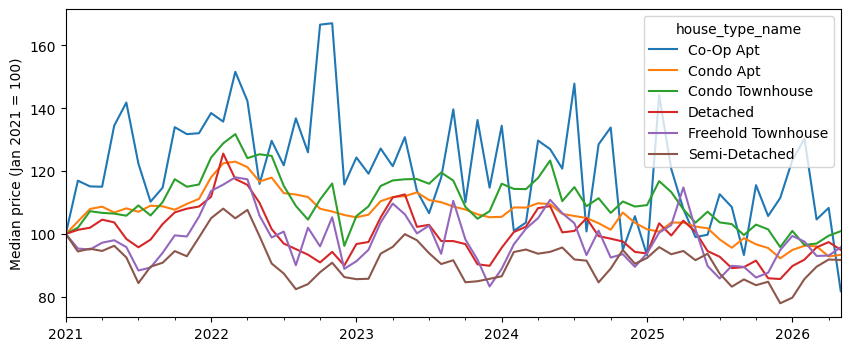

In [10]:
monthly = (df.groupby([df["date_sold"].dt.to_period("M"), "house_type_name"])["sold_price"]
             .median()
             .unstack())
index = monthly / monthly.iloc[0] * 100      # every type starts at 100 in Jan 2021
index.plot(figsize=(10, 4), ylabel="Median price (Jan 2021 = 100)", xlabel="")

print("Peak month per type:")
print(index.idxmax())
print("\nLast month vs. peak (%):")
print((index.iloc[-1] / index.max() * 100 - 100).round(1))

From the chart,  we can see that the median price rises in the Spring and falls in the winter. We might need the sold months for our model.

count    150000.000
mean          1.002
std           0.107
min           0.800
10%           0.890
25%           0.928
50%           0.980
75%           1.053
90%           1.147
max           1.700
Name: sale_to_list, dtype: float64

Share sold ABOVE asking: 0.416

Median ratio by type:
house_type_name
Co-Op Apt             0.960
Condo Apt             0.965
Condo Townhouse       0.997
Detached              0.995
Freehold Townhouse    1.004
Semi-Detached         1.026
Name: sale_to_list, dtype: float64


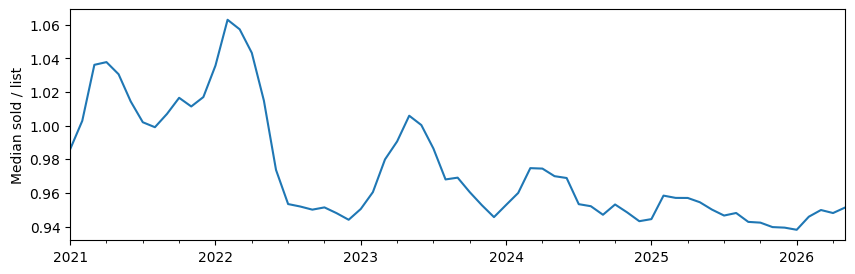

In [12]:
df["sale_to_list"] = df["sold_price"]/df["list_price"]
print(df["sale_to_list"].describe(percentiles=[.1, .25, .5, .75, .9]).round(3))
print("\nShare sold ABOVE asking:", round((df["sale_to_list"] > 1).mean(), 3))
print("\nMedian ratio by type:")
print(df.groupby("house_type_name")["sale_to_list"].median().round(3))
ratio_by_month = df.groupby(df["date_sold"].dt.to_period("M"))["sale_to_list"].median()
ratio_by_month.plot(figsize=(10, 3), ylabel="Median sold / list", xlabel="");

We can see from the chart: Bidding War during the 2022 Boom, flipped fast after that, Spring rise shrinks year by year, Recent trend is predictablt.

In [ ]:
area = df["house_area"].astype(str)
is_range = area.str.contains("-")

print("Share given as a range:", round(is_range.mean(), 3))
print("\nShare that are ranges, by type:")
print(is_range.groupby(df["house_type_name"]).mean().round(3))
print("\nMost common ranges:")
print(area[is_range].value_counts().head(12))

not_number = pd.to_numeric(area[~is_range], errors="coerce").isna()
print("\nNon-range values that are NOT plain numbers:", not_number.sum())
print(area[~is_range][not_number].value_counts().head(10))

Share given as a range: 0.4

Share that are ranges, by type:
house_type_name
Co-Op Apt             0.421
Condo Apt             0.400
Condo Townhouse       0.398
Detached              0.401
Freehold Townhouse    0.402
Semi-Detached         0.400
Name: house_area, dtype: float64

Most common ranges:
house_area
700-899      6282
600-799      6101
800-999      4298
900-1099     3934
1000-1199    3714
1100-1299    3648
1200-1399    3426
500-699      3422
1300-1499    3250
1400-1599    2815
1500-1699    2472
1600-1799    2121
Name: count, dtype: int64

Non-range values that are NOT plain numbers: 0
Series([], Name: count, dtype: int64)


In [14]:
from features import square_feet

df["sqft"] = square_feet(df["house_area"])

parts = area[is_range].str.split("-", expand=True).astype(float)
print("Range widths:")
print((parts[1] - parts[0]).value_counts().head())

print("\nSquare feet by type:")
print(df.groupby("house_type_name")["sqft"]
        .describe(percentiles=[.01, .5, .99])[["min", "1%", "50%", "99%", "max"]].round(0))

df["price_per_sqft"] = df["sold_price"] / df["sqft"]
print("\nMedian $ per sq ft (False = exact number, True = range):")
print(df.groupby(["house_type_name", is_range])["price_per_sqft"].median().unstack().round(0))

Range widths:
199.0    60031
Name: count, dtype: int64

Square feet by type:
                      min     1%     50%     99%     max
house_type_name                                         
Co-Op Apt           357.0  500.0   900.0  1971.0  3500.0
Condo Apt           300.0  459.0   800.0  2005.0  5980.0
Condo Townhouse     373.0  615.0  1297.0  2549.0  4200.0
Detached            374.0  720.0  1800.0  6925.0  9100.0
Freehold Townhouse  700.0  900.0  1700.0  3434.0  5600.0
Semi-Detached       680.0  872.0  1474.0  3800.0  9000.0

Median $ per sq ft (False = exact number, True = range):
house_area          False  True 
house_type_name                 
Co-Op Apt           759.0  729.0
Condo Apt           832.0  782.0
Condo Townhouse     638.0  612.0
Detached            774.0  752.0
Freehold Townhouse  698.0  681.0
Semi-Detached       817.0  776.0


The range is fixed for all 60031 values, now we can find strange value:

In [15]:
cols = ["bedrooms", "washrooms", "parking_total", "garage",
        "lot_front", "lot_depth", "sqft", "latitude", "longitude"]
df[cols].describe().round(2)

,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,sqft,latitude,longitude
count,150000.00,150000.00,150000.00,150000.00,62737.00,62737.00,150000.00,150000.00,150000.00
mean,2.34,2.16,1.85,0.41,36.33,119.33,1380.16,43.64,-79.38
std,1.11,1.11,1.65,0.71,17.61,30.69,898.54,0.05,0.10
min,0.00,1.00,0.00,0.00,10.00,40.00,300.00,43.49,-79.60
25%,1.00,1.00,1.00,0.00,22.93,98.87,799.50,43.60,-79.45
50%,2.00,2.00,1.00,0.00,32.53,116.65,1142.00,43.64,-79.39
75%,3.00,3.00,3.00,1.00,46.06,136.92,1644.00,43.68,-79.31
max,6.00,6.00,6.00,6.00,150.00,300.00,9099.50,43.84,-79.07


In [16]:
print(df["bedrooms"].value_counts().sort_index())
print(df["washrooms"].value_counts().sort_index())

bedrooms
0     2232
1    36337
2    45385
3    44985
4    17046
5     3085
6      930
Name: count, dtype: int64
washrooms
1    43096
2    67202
3    21974
4    10932
5     4179
6     2617
Name: count, dtype: int64


In [17]:
show = ["house_type_name", "sqft", "house_area", "bedrooms", "washrooms",
        "sold_price", "price_per_sqft", "community"]

print("Biggest semis:")
display(df[df["house_type_name"] == "Semi-Detached"].nlargest(5, "sqft")[show])

print("Biggest condo apartments:")
display(df[df["house_type_name"] == "Condo Apt"].nlargest(5, "sqft")[show])

print("Smallest detached houses:")
display(df[df["house_type_name"] == "Detached"].nsmallest(5, "sqft")[show])

Biggest semis:


,house_type_name,sqft,house_area,bedrooms,washrooms,sold_price,price_per_sqft,community
9941,Semi-Detached,9000.0,9000,6,6,5671200.0,630.133333,Lindenglen
67836,Semi-Detached,8799.5,8700-8899,5,4,3366500.0,382.578556,Beechglen
122113,Semi-Detached,8399.5,8300-8499,3,6,11839300.0,1409.524376,Lindenglen
146759,Semi-Detached,7499.5,7400-7599,6,6,2227900.0,297.073138,Lindenglen
96134,Semi-Detached,6886.0,6886,6,5,5811900.0,844.016846,Beechglen


Biggest condo apartments:


,house_type_name,sqft,house_area,bedrooms,washrooms,sold_price,price_per_sqft,community
17238,Condo Apt,5980.0,5980,4,4,2183800.0,365.183946,Elmview
59880,Condo Apt,5099.5,5000-5199,4,5,4471800.0,876.909501,Elmview
146452,Condo Apt,5099.5,5000-5199,4,5,2583800.0,506.677125,Elmview
25373,Condo Apt,4699.5,4600-4799,3,3,1613000.0,343.228003,Hawthornbourne
4640,Condo Apt,4552.0,4552,3,3,3432600.0,754.086116,Elmview


Smallest detached houses:


,house_type_name,sqft,house_area,bedrooms,washrooms,sold_price,price_per_sqft,community
10438,Detached,374.0,374,0,1,1048600.0,2803.743316,Walnutfield
39376,Detached,397.0,397,1,1,531300.0,1338.287154,Hawthorncliffe
40763,Detached,399.5,300-499,1,1,597300.0,1495.118899,Cypressbrook
97768,Detached,399.5,300-499,1,1,633900.0,1586.733417,Hemlockhollow
141492,Detached,399.5,300-499,0,1,501000.0,1254.067584,Dogwoodhaven


In [18]:
type_median = df.groupby("house_type_name")["price_per_sqft"].transform("median")
odd = (df["price_per_sqft"] < type_median / 3) | (df["price_per_sqft"] > type_median * 3)

print("Homes with $/sq ft under 1/3 or over 3x their type's median:", odd.sum())
display(df[odd][show].head(10))

Homes with $/sq ft under 1/3 or over 3x their type's median: 402


,house_type_name,sqft,house_area,bedrooms,washrooms,sold_price,price_per_sqft,community
1022,Condo Apt,1799.5,1700-1899,2,2,420900.0,233.898305,Dogwoodmills
1087,Condo Apt,1099.5,1000-1199,2,2,297200.0,270.304684,Cypressglen
1195,Condo Apt,1714.0,1714,3,2,460700.0,268.786464,Cypressglen
1226,Detached,724.0,724,3,2,1734400.0,2395.580110,Maplevale
1415,Condo Apt,1599.5,1500-1699,2,1,429800.0,268.708972,Chestnutbank
1784,Condo Apt,2229.0,2229,2,2,490500.0,220.053836,Maplebrook
2093,Condo Apt,1299.5,1200-1399,2,1,350200.0,269.488265,Balsamcrest
2329,Detached,1464.0,1464,4,3,3441700.0,2350.887978,Willowpark
3058,Freehold Townhouse,2499.5,2400-2599,3,2,5815000.0,2326.465293,Lindenglen
3470,Condo Apt,1199.5,1100-1299,2,2,312200.0,260.275115,Balsamcrest


In [19]:
test_off = data.load("off_market")
test_list = data.load("list_aware")

for name, t in [("off_market", test_off), ("list_aware", test_list)]:
    t = t.assign(sqft=square_feet(t["house_area"]))
    print(name)
    display(t[cols].describe().loc[["min", "max"]].round(2))

off_market


,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,sqft,latitude,longitude
min,0.0,1.0,0.0,0.0,10.00,40.00,359.0,43.49,-79.59
max,6.0,6.0,6.0,4.0,129.11,295.21,9099.5,43.83,-79.08


list_aware


,bedrooms,washrooms,parking_total,garage,lot_front,lot_depth,sqft,latitude,longitude
min,0.0,1.0,0.0,0.0,10.00,40.00,350.0,43.49,-79.59
max,6.0,6.0,6.0,6.0,127.05,282.88,9000.0,43.84,-79.09
